# 01 - Exploratory Data Analysis

**Goal:** understand the cleaned *Online Retail II* transactions before building features and models.

**Data:** every invoice line of a UK online gift retailer (December 2009 - December 2011), after the cleaning stage (`python -m src.data.cleaner`). Cancellations are kept and flagged with `is_cancellation`.

**Questions answered here**
1. How big is the data and is it complete?
2. How do revenue and orders change over time (trend and seasonality)?
3. Where does the revenue come from (countries, products, customers)?
4. How do people shop (basket size, weekday, time of day)?
5. How common are cancellations and unusual quantities?

In [1]:
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

# Work from the project root no matter where Jupyter was started.
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src.utils.config import get_config_value, resolve_path

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3})
print("Project folder:", ROOT)

Project folder: e:\customer-behavior-prediction


## 1. Load the cleaned transactions

In [2]:
path = resolve_path(get_config_value("paths.interim_transactions", "data/interim/transactions_clean.parquet"))
tx = pd.read_parquet(path)
print(f"{len(tx):,} rows x {tx.shape[1]} columns")
display(tx.head())
display(tx.dtypes.to_frame("dtype"))

805,908 rows x 13 columns


,invoice,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,source_sheet,is_cancellation,is_bulk_order,is_quantity_outlier,line_total
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.950,13085,United Kingdom,Year 2009-2010,False,False,False,83.400
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,13085,United Kingdom,Year 2009-2010,False,False,False,81.000
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,13085,United Kingdom,Year 2009-2010,False,False,False,81.000
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.100,13085,United Kingdom,Year 2009-2010,False,False,True,100.800
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.250,13085,United Kingdom,Year 2009-2010,False,False,False,30.000


,dtype
invoice,string
stock_code,string
description,string
quantity,int64
invoice_date,datetime64[us]
unit_price,float64
customer_id,int64
country,string
source_sheet,str
is_cancellation,bool


## 2. Size and coverage

In [3]:
summary = pd.Series(
    {
        "invoice lines": len(tx),
        "invoices": tx["invoice"].nunique(),
        "customers": tx["customer_id"].nunique(),
        "products (stock codes)": tx["stock_code"].nunique(),
        "countries": tx["country"].nunique(),
        "first invoice": tx["invoice_date"].min(),
        "last invoice": tx["invoice_date"].max(),
    }
)
display(summary.to_frame("value"))

missing = tx.isna().mean().sort_values(ascending=False)
print("Share of missing values per column (only columns with gaps):")
display(missing[missing > 0].to_frame("missing share") if (missing > 0).any() else "No missing values after cleaning")

,value
invoice lines,805908
invoices,43954
customers,5894
products (stock codes),4638
countries,41
first invoice,2009-12-01 07:45:00
last invoice,2011-12-09 12:50:00


Share of missing values per column (only columns with gaps):


'No missing values after cleaning'

## 3. Revenue and orders over time

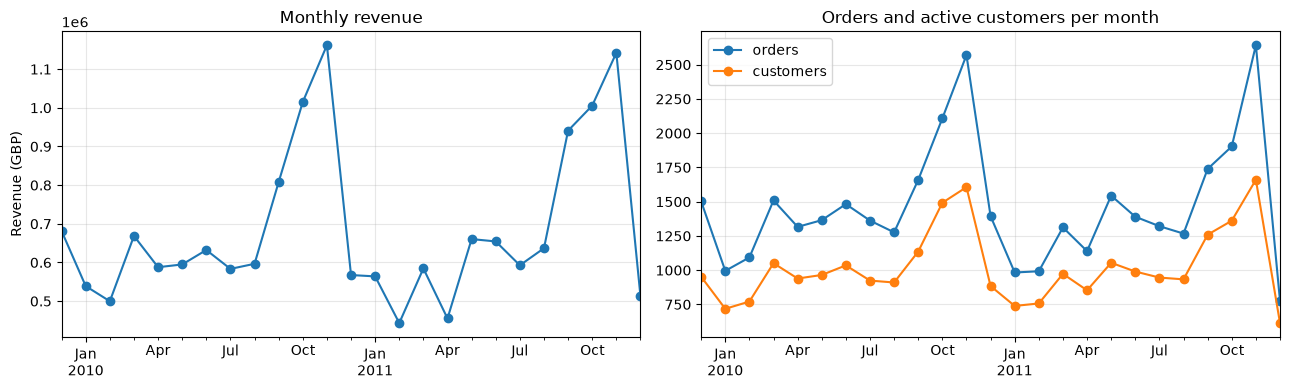

Best month: November 2010 with GBP 1,161,854


In [4]:
sales = tx[~tx["is_cancellation"]].copy()
sales["month"] = sales["invoice_date"].dt.to_period("M").dt.to_timestamp()
monthly = sales.groupby("month").agg(revenue=("line_total", "sum"), orders=("invoice", "nunique"), customers=("customer_id", "nunique"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
monthly["revenue"].plot(ax=axes[0], marker="o", color="tab:blue")
axes[0].set(title="Monthly revenue", xlabel="", ylabel="Revenue (GBP)")
monthly[["orders", "customers"]].plot(ax=axes[1], marker="o")
axes[1].set(title="Orders and active customers per month", xlabel="")
plt.tight_layout()
plt.show()

best = monthly["revenue"].idxmax()
print(f"Best month: {best:%B %Y} with GBP {monthly.loc[best, 'revenue']:,.0f}")

Revenue climbs towards the end of every year (gift shopping before Christmas). This **seasonality** is why the project has a *seasonal order share* feature and a *Seasonal Shoppers* segment.

## 4. Where the revenue comes from

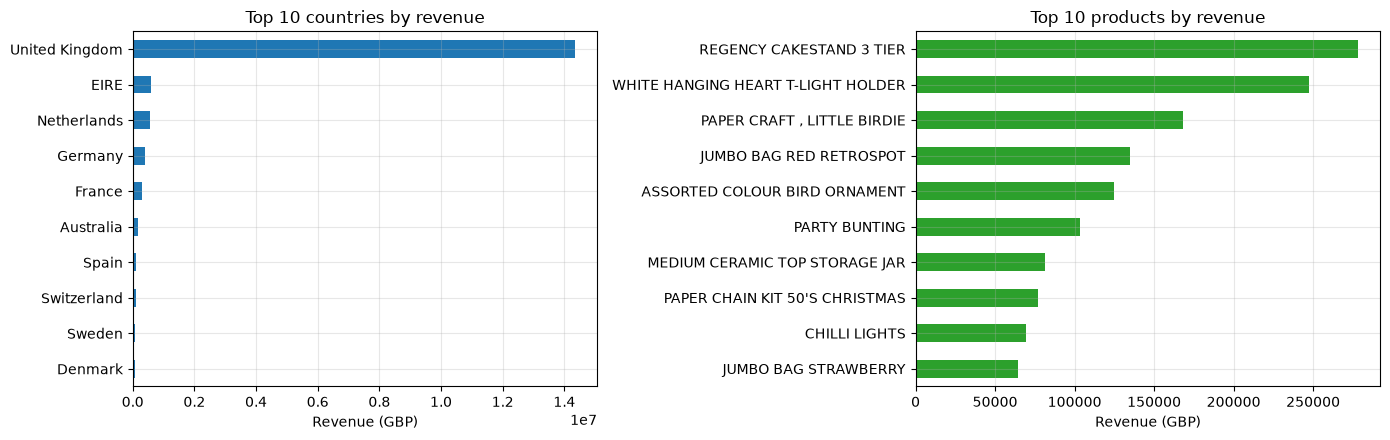

Top country share of revenue: 83.8% (United Kingdom)


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

by_country = sales.groupby("country")["line_total"].sum().sort_values(ascending=False).head(10)[::-1]
by_country.plot.barh(ax=axes[0], color="tab:blue")
axes[0].set(title="Top 10 countries by revenue", xlabel="Revenue (GBP)", ylabel="")

by_product = sales.groupby("description")["line_total"].sum().sort_values(ascending=False).head(10)[::-1]
by_product.plot.barh(ax=axes[1], color="tab:green")
axes[1].set(title="Top 10 products by revenue", xlabel="Revenue (GBP)", ylabel="")
plt.tight_layout()
plt.show()

share = sales.groupby("country")["line_total"].sum().sort_values(ascending=False)
print(f"Top country share of revenue: {share.iloc[0] / share.sum():.1%} ({share.index[0]})")

## 5. Customers: how often and how much do they buy?

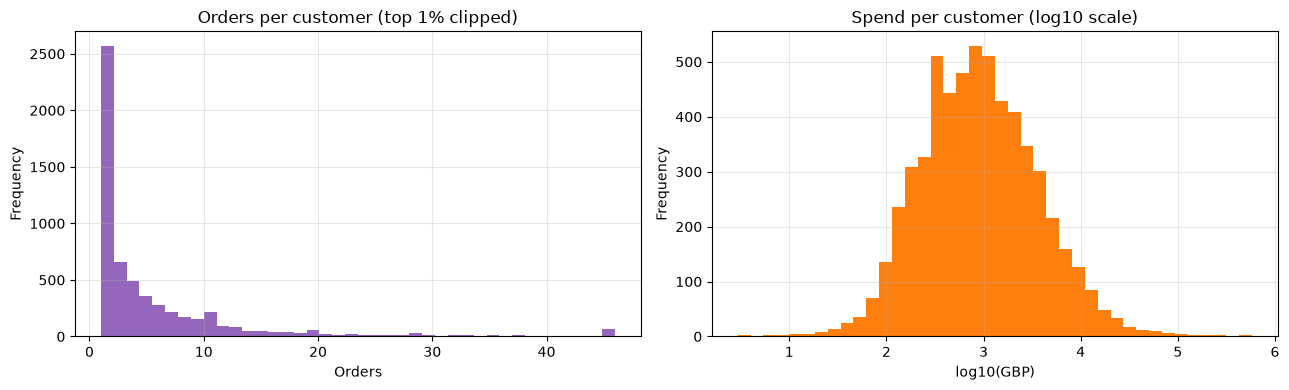

The top 10% of customers bring 63.8% of the revenue
Customers with a single order: 27.7%


,orders,spend
count,"5,861.000","5,861.000"
mean,6.251,"2,922.613"
std,12.775,"14,306.139"
min,1.000,2.950
25%,1.000,340.500
50%,3.000,856.030
75%,7.000,"2,246.750"
max,376.000,"580,987.040"


In [6]:
per_customer = sales.groupby("customer_id").agg(
    orders=("invoice", "nunique"),
    spend=("line_total", "sum"),
    first=("invoice_date", "min"),
    last=("invoice_date", "max"),
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
per_customer["orders"].clip(upper=per_customer["orders"].quantile(0.99)).plot.hist(bins=40, ax=axes[0], color="tab:purple")
axes[0].set(title="Orders per customer (top 1% clipped)", xlabel="Orders")
np.log10(per_customer["spend"].clip(lower=1)).plot.hist(bins=40, ax=axes[1], color="tab:orange")
axes[1].set(title="Spend per customer (log10 scale)", xlabel="log10(GBP)")
plt.tight_layout()
plt.show()

top_10_percent = per_customer["spend"].sort_values(ascending=False).head(int(len(per_customer) * 0.1)).sum()
print(f"The top 10% of customers bring {top_10_percent / per_customer['spend'].sum():.1%} of the revenue")
print(f"Customers with a single order: {(per_customer['orders'] == 1).mean():.1%}")
display(per_customer[["orders", "spend"]].describe())

Revenue is usually concentrated in a minority of customers (see the top-10% share printed above), and many customers buy only once or twice. That makes **future revenue hard to predict** and is why the project ranks customers by *churn probability x past spend*.

## 6. How people shop

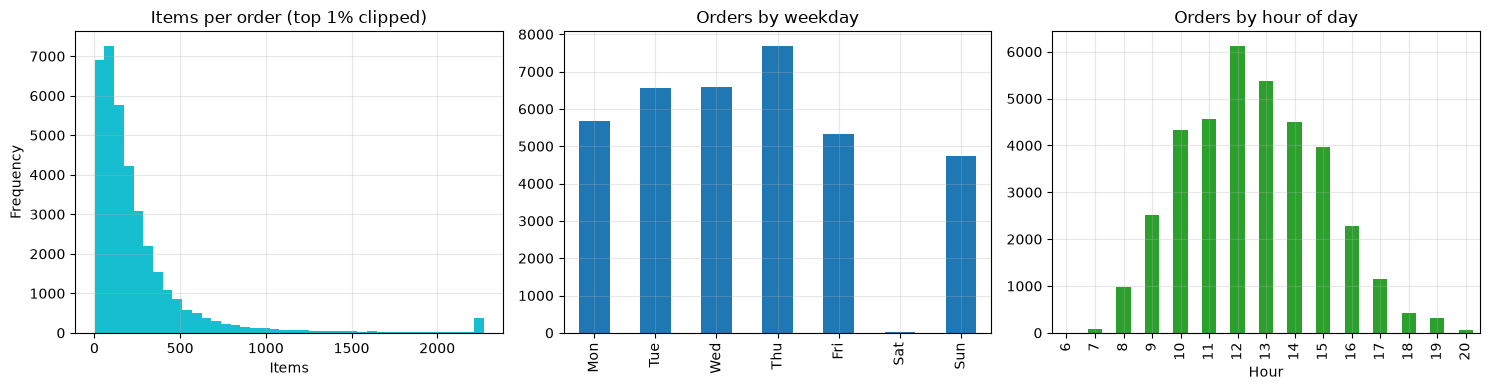

In [7]:
orders = sales.groupby("invoice").agg(items=("quantity", "sum"), value=("line_total", "sum"), when=("invoice_date", "first"))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
orders["items"].clip(upper=orders["items"].quantile(0.99)).plot.hist(bins=40, ax=axes[0], color="tab:cyan")
axes[0].set(title="Items per order (top 1% clipped)", xlabel="Items")

weekday = orders["when"].dt.dayofweek.value_counts().sort_index()
weekday.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"][: len(weekday)] if len(weekday) == 7 else weekday.index
weekday.plot.bar(ax=axes[1], color="tab:blue")
axes[1].set(title="Orders by weekday", xlabel="")

orders["when"].dt.hour.value_counts().sort_index().plot.bar(ax=axes[2], color="tab:green")
axes[2].set(title="Orders by hour of day", xlabel="Hour")
plt.tight_layout()
plt.show()

## 7. Cancellations and unusual quantities

In [8]:
cancel_share = tx["is_cancellation"].mean()
print(f"Cancellation lines: {tx['is_cancellation'].sum():,} ({cancel_share:.1%} of all lines)")
print(f"Bulk-order lines (flagged): {tx['is_bulk_order'].sum():,}")
print(f"Quantity-outlier lines (flagged): {tx['is_quantity_outlier'].sum():,}")

returns = tx[tx["is_cancellation"]].groupby("customer_id").size()
print(f"Customers with at least one return: {len(returns):,} of {tx['customer_id'].nunique():,}")

flagged = tx.loc[tx["is_quantity_outlier"], ["invoice", "description", "quantity", "unit_price", "customer_id"]]
display(flagged.sort_values("quantity", ascending=False).head(10))

Cancellation lines: 17,674 (2.2% of all lines)
Bulk-order lines (flagged): 357
Quantity-outlier lines (flagged): 37,595
Customers with at least one return: 2,464 of 5,894


,invoice,description,quantity,unit_price,customer_id
805434,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.080,16446
438975,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.040,12346
65192,497946,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.100,13902
94036,501534,SET/6 WOODLAND PAPER PLATES,12960,0.100,13902
94034,501534,SET/6 STRAWBERRY PAPER CUPS,12960,0.100,13902
94037,501534,SET/6 WOODLAND PAPER CUPS,12744,0.100,13902
94035,501534,SET/6 STRAWBERRY PAPER PLATES,12480,0.100,13902
100677,502269,PACK OF 12 PINK PAISLEY TISSUES,10000,0.250,17940
100680,502269,PACK OF 12 WOODLAND TISSUES,10000,0.250,17940
100679,502269,PACK OF 12 RED SPOTTY TISSUES,10000,0.250,17940


## 8. Findings that shaped the project

- **Strong seasonality** - revenue peaks before Christmas, so features describe *when* customers buy, not only how much.
- **Concentrated revenue** - a minority of customers generates most of the revenue, so predicting lifetime value is hard and a log transform is used for the CLV models.
- **Many one-off buyers** - churn is the majority outcome (about 57% of customers do not return within 90 days), which is why the models use balanced class weights and a validation-chosen threshold.
- **Returns and bulk orders exist** - they are flagged rather than deleted, and return rate is a customer feature.
- **Guest checkouts without a customer ID** are removed, because every model works at customer level.

Next: `02_feature_engineering.ipynb`.